# 01b: Keşifsel Veri Analizi ve Özellik Seçimi (Kişi 1)

**Proje:** Framingham Kalp Çalışması verisi ile inme (stroke) tahmini

**Girdi:** `01_data_preprocessing` notebook'unun ürettiği `train.csv` ve `test.csv`.

**Bu notebook'ta yapılanlar:**
2. Eğitim verisine genel bakış ve sınıf dağılımı
3. Sürekli değişkenlerin dağılımı: inme olan ve olmayan kişilerde histogramlar
4. Yaş ve tansiyon gruplarına göre inme oranı
5. İkili (0/1) risk faktörlerinde inme oranı
6. Korelasyon analizi (ısı haritası)
7. Scatter plot: yaş ve büyük tansiyon
8. İstatistiksel testler: hangi özellik inme grubunda gerçekten farklı?
9. Özellik önemi: mutual information
10. Özellik seçimi deneyi: daha az özellikle model daha iyi olur mu?
11. Özet (rapor için)

**Neden yalnızca eğitim verisi?** Test seti en sonda, modeli bir kez değerlendirmek için ayrıldı. Grafiklere ve özellik seçimine test verisi de katılsaydı, test setindeki bilgi dolaylı olarak kararlarımıza karışırdı. Bu yüzden bu notebook'taki tüm analizler yalnızca eğitim verisi (`train.csv`) üzerinde yapılır.

## 1. Kurulum ve veri

Ortak sabitler `src/config.py`, veri yükleme ve ön işleme `src/preprocessing.py`, CV bölmesi `src/metrics.py` dosyasından gelir. Colab'da bu `.py` dosyalarını ve `train.csv`, `test.csv` dosyalarını sol menüden yükleyin.

In [1]:
import sys
import warnings
from pathlib import Path

# Repo: ../src. Colab: the src/*.py files uploaded to the working directory.
SRC_DIR = next((p for p in (Path("../src"), Path("src"), Path(".")) if (p / "config.py").exists()), None)
if SRC_DIR is None:
    raise FileNotFoundError("config.py bulunamadı. Colab'da src klasöründeki .py dosyalarını sol menüden yükleyin.")
sys.path.insert(0, str(SRC_DIR.resolve()))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from scipy import stats
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

from config import RANDOM_STATE, TARGET
from metrics import shared_cv
from preprocessing import BINARY, CONTINUOUS, build_preprocessor, load_data

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

X_train, X_test, y_train, y_test = load_data()   # X_test / y_test are not used in this notebook
train = X_train.assign(**{TARGET: y_train})
LABELS = {0: "İnme yok", 1: "İnme var"}
COLORS = {"İnme yok": "#4C72B0", "İnme var": "#C44E52"}
train["grup"] = train[TARGET].map(LABELS)

print("Eğitim verisi:", X_train.shape)

Eğitim verisi: (3521, 17)


## 2. Genel bakış ve sınıf dağılımı

In [2]:
counts = y_train.value_counts().sort_index()
print(pd.DataFrame({"kişi": counts, "yüzde": (counts / len(y_train) * 100).round(2)},
                   index=pd.Index([0, 1], name=TARGET)).rename(index=LABELS))
print(f"\nDengesizlik oranı: her 1 inme vakasına {counts[0] / counts[1]:.1f} sağlıklı kişi düşüyor.")

          kişi  yüzde
STROKE               
İnme yok  3215  91.31
İnme var   306   8.69

Dengesizlik oranı: her 1 inme vakasına 10.5 sağlıklı kişi düşüyor.


In [3]:
# Mean of every feature in the two groups: a first look at which values differ
group_means = train.groupby("grup")[CONTINUOUS + BINARY].mean().T.round(2)
group_means["fark (inme var - yok)"] = (group_means["İnme var"] - group_means["İnme yok"]).round(2)
group_means

grup,İnme var,İnme yok,fark (inme var - yok)
AGE,55.22,49.31,5.91
TOTCHOL,243.26,236.45,6.81
SYSBP,146.38,131.67,14.71
DIABP,89.39,82.58,6.81
BMI,26.75,25.73,1.02
HEARTRTE,75.56,75.95,-0.39
GLUCOSE,84.79,81.53,3.26
CIGPDAY,9.04,9.04,0.00
CURSMOKE,0.50,0.50,0.00
DIABETES,0.07,0.02,0.05


**Yorum:**
- Eğitim verisinde 3.521 kişi var; 306'sı (%8,7) takip süresince inme geçirmiş. Her inme vakasına yaklaşık 10,5 sağlıklı kişi düşüyor, yani veri belirgin şekilde **dengesiz**. Bu yüzden modeller accuracy ile değil PR-AUC ve recall ile değerlendirildi, eğitimde SMOTE / `class_weight` kullanıldı (bkz. `02` ve `03`).
- Grup ortalamalarına bakınca inme geçirenler ortalama **6 yaş daha büyük**, büyük tansiyonları **15 mmHg**, küçük tansiyonları 7 mmHg **daha yüksek**. Hipertansiyon öyküsü (`PREVHYP`) inme grubunda %58, diğer grupta %30. Diyabet (%7'ye %2) ve tansiyon ilacı kullanımı (%8'e %3) da inme grubunda daha sık.
- Dikkat çekici bir nokta: **sigara** (`CURSMOKE`, `CIGPDAY`) iki grupta neredeyse aynı (%50, günde ortalama 9 sigara). Bölüm 5'te bu konuya geri dönülecek.

## 3. Sürekli değişkenlerin dağılımı

Her sürekli değişken için inme olan ve olmayan kişilerin histogramı üst üste çizilir. İki grubun sayıları çok farklı olduğu için (yaklaşık 10'a 1) histogramlar **yoğunluğa** göre normalize edilmiştir: her grubun alanı 1'dir, böylece şekiller karşılaştırılabilir. Kesikli çizgiler grup medyanlarıdır.

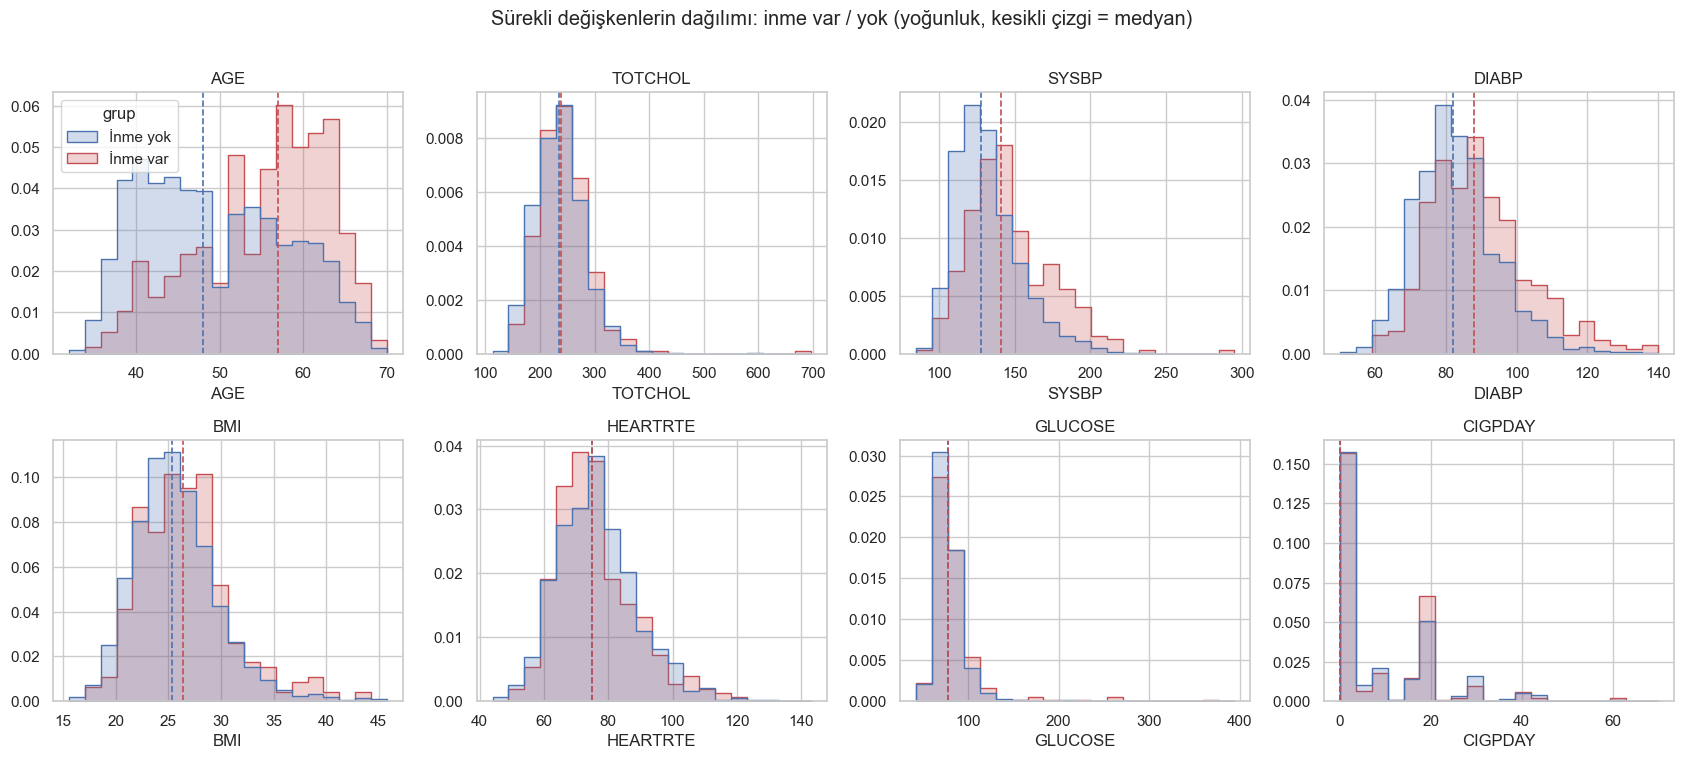

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(17, 7.5))
for ax, col in zip(axes.ravel(), CONTINUOUS):
    sns.histplot(data=train, x=col, hue="grup", stat="density", common_norm=False,
                 bins=20, element="step", palette=COLORS, ax=ax, legend=(col == CONTINUOUS[0]))
    for name, color in COLORS.items():
        ax.axvline(train.loc[train["grup"] == name, col].median(), color=color, linestyle="--", linewidth=1.2)
    ax.set_title(col)
    ax.set_ylabel("")
plt.suptitle("Sürekli değişkenlerin dağılımı: inme var / yok (yoğunluk, kesikli çizgi = medyan)", y=1.01)
plt.tight_layout()
plt.show()

In [5]:
# Skewness: values far from 0 mean a long tail (relevant for distance-based models and scaling)
train[CONTINUOUS].skew().round(2).sort_values(ascending=False).to_frame("çarpıklık (skewness)")

,çarpıklık (skewness)
GLUCOSE,6.59
CIGPDAY,1.23
SYSBP,1.11
TOTCHOL,0.95
BMI,0.92
DIABP,0.70
HEARTRTE,0.64
AGE,0.20


**Yorum:**
- **`AGE`**, **`SYSBP`** ve **`DIABP`** dağılımları inme grubunda açıkça sağa kaymış. Yaş medyanı inme grubunda 57, diğer grupta 48. Tansiyonda inme grubunun sağ kuyruğu (çok yüksek değerler) çok daha kalın. `BMI`'da da küçük bir kayma var.
- **`TOTCHOL`, `HEARTRTE`, `GLUCOSE`, `CIGPDAY`** dağılımları iki grupta neredeyse üst üste. Bu değişkenler tek başına inme grubunu ayırt etmiyor.
- **Çarpıklık:** `GLUCOSE` çok sağa çarpık (6,6). Değerlerin çoğu 70–100 arasında, birkaç kişide (çoğu diyabetli) 200–400'e çıkıyor. `CIGPDAY` sıfırda yığılmış (sigara içmeyenler), `SYSBP` de sağa çarpık. 01 numaralı notebook'ta açıklandığı gibi bu yüksek değerler klinik olarak gerçek olduğu için silinmedi. Ağaç tabanlı modeller değerlerin sırasına baktığı için çarpıklıktan etkilenmez.
- Yaş histogramındaki dişli görünüm, katılımcıların yaşının tam sayı olarak kaydedilmesinden kaynaklanır; bir veri hatası değildir.

## 4. Yaş ve tansiyon gruplarına göre inme oranı

Histogramlar dağılımın şeklini gösterir. Risk ile ilişkiyi daha doğrudan görmek için kişiler yaş ve büyük tansiyon gruplarına ayrılır ve her grupta inme geçirenlerin oranı hesaplanır. Çubukların üzerindeki sayı o gruptaki kişi sayısıdır.

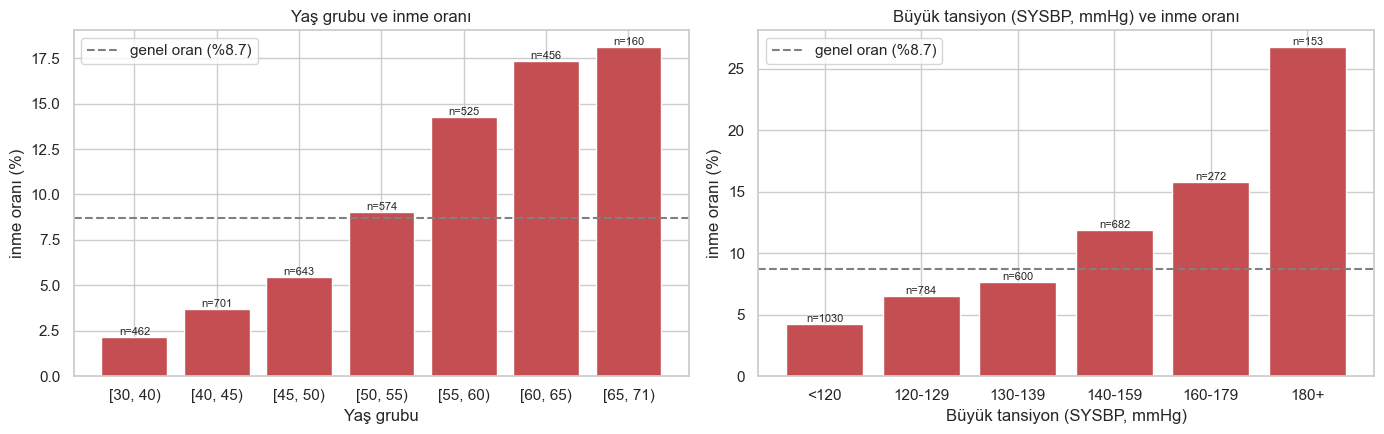

In [6]:
age_group = pd.cut(train["AGE"], bins=[30, 40, 45, 50, 55, 60, 65, 71], right=False)
sbp_group = pd.cut(train["SYSBP"], bins=[0, 120, 130, 140, 160, 180, 400], right=False,
                   labels=["<120", "120-129", "130-139", "140-159", "160-179", "180+"])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, (title, grp) in zip(axes, [("Yaş grubu", age_group), ("Büyük tansiyon (SYSBP, mmHg)", sbp_group)]):
    rate = y_train.groupby(grp, observed=True).mean() * 100
    n = y_train.groupby(grp, observed=True).size()
    bars = ax.bar(rate.index.astype(str), rate.values, color="#C44E52")
    ax.bar_label(bars, labels=[f"n={v}" for v in n.values], fontsize=8)
    ax.axhline(y_train.mean() * 100, color="gray", linestyle="--", label=f"genel oran (%{y_train.mean() * 100:.1f})")
    ax.set_title(f"{title} ve inme oranı")
    ax.set_xlabel(title)
    ax.set_ylabel("inme oranı (%)")
    ax.legend()
plt.tight_layout()
plt.show()

**Yorum:**
- **Yaş:** İnme oranı yaşla birlikte düzenli olarak artıyor: 30–39 yaşta %2,2, 50–54'te %9,1, 65 ve üstünde %18,1. En genç ve en yaşlı grup arasında yaklaşık **8 kat** fark var.
- **Büyük tansiyon:** 120 mmHg altında %4,3, 140–159'da %11,9, 180 ve üstünde %26,8 (yaklaşık **6 kat**). Oran, **140 mmHg** (evre 2 hipertansiyon) eşiğinden sonra genel ortalamanın (%8,7) üstüne çıkıyor.
- Bu iki grafik, `02`'de eklenen `bp_stage` (ACC/AHA tansiyon evresi) özelliğinin gerekçesini veride de doğruluyor: risk, klinik tansiyon eşiklerinde belirgin şekilde artıyor.

## 5. İkili (0/1) risk faktörleri

Sigara, diyabet, tansiyon ilacı ve önceki kalp hastalıkları gibi evet/hayır özelliklerinde, özelliği taşıyan ve taşımayan kişilerin inme oranları karşılaştırılır. **Göreli risk** = (özellik varken inme oranı) / (özellik yokken inme oranı). 1'den büyükse özellik inme riskiyle birlikte artıyor demektir.

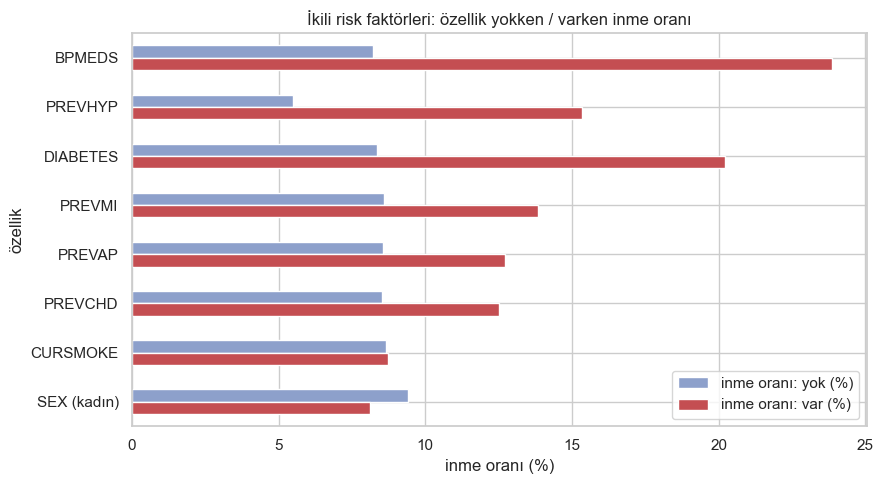

,taşıyan kişi,inme oranı: var (%),inme oranı: yok (%),göreli risk
özellik,,,,
BPMEDS,109,23.85,8.21,2.91
PREVHYP,1147,15.34,5.48,2.80
DIABETES,99,20.20,8.36,2.42
PREVMI,65,13.85,8.59,1.61
PREVAP,118,12.71,8.55,1.49
PREVCHD,152,12.50,8.52,1.47
CURSMOKE,1744,8.72,8.67,1.01
SEX (kadın),1980,8.13,9.41,0.86


In [7]:
rows = []
for col in BINARY + ["SEX"]:
    yes_value = 2 if col == "SEX" else 1          # SEX: 1 = male, 2 = female
    has = train[col] == yes_value
    rows.append({"özellik": "SEX (kadın)" if col == "SEX" else col,
                 "taşıyan kişi": int(has.sum()),
                 "inme oranı: var (%)": y_train[has].mean() * 100,
                 "inme oranı: yok (%)": y_train[~has].mean() * 100})
binary_table = pd.DataFrame(rows).set_index("özellik")
binary_table["göreli risk"] = binary_table["inme oranı: var (%)"] / binary_table["inme oranı: yok (%)"]
binary_table = binary_table.sort_values("göreli risk", ascending=False).round(2)

ax = binary_table[["inme oranı: yok (%)", "inme oranı: var (%)"]].plot(
    kind="barh", figsize=(9, 5), color=["#8DA0CB", "#C44E52"])
ax.set_xlabel("inme oranı (%)")
ax.set_title("İkili risk faktörleri: özellik yokken / varken inme oranı")
ax.invert_yaxis()
plt.tight_layout()
plt.show()
binary_table

**Yorum:**
- En güçlü ikili risk faktörleri **tansiyon ilacı kullanımı** (`BPMEDS`, göreli risk 2,9), **hipertansiyon öyküsü** (`PREVHYP`, 2,8) ve **diyabet** (`DIABETES`, 2,4). Tansiyon ilacı kullanan biri zaten tanı almış ve muhtemelen ağır bir hipertansiyon hastasıdır; bu yüzden `BPMEDS` de aslında tansiyonun dolaylı bir göstergesi.
- Önceki kalp hastalıkları (`PREVMI`, `PREVAP`, `PREVCHD`) riski 1,5–1,6 kat artırıyor gibi görünüyor. Ancak bu grupların her birinde yalnızca 65–152 kişi var, bu yüzden tahminleri belirsiz (Bölüm 8'deki testlerde anlamlı çıkmadılar).
- **Sigara (`CURSMOKE`) bu veride inme oranını değiştirmiyor** (göreli risk 1,01). Sigara literatürde bilinen bir inme risk faktörü olduğu için bu şaşırtıcı. Olası bir açıklama **karıştırıcı etki (confounding)**: bu veride sigara içenler ortalama 47,9, içmeyenler 51,7 yaşında. Sigara içenler daha genç olduğu için, yaşın düşürdüğü risk sigaranın artırdığı riski gölgeliyor olabilir. Tek değişkenli analiz bu iki etkiyi ayıramaz, çok değişkenli modeller ise ayırabilir.
- Kadınlarda inme oranı erkeklerden biraz düşük (göreli risk 0,86), fark anlamlı değil.

## 6. Korelasyon analizi

Özellikler arasındaki ve özelliklerle hedef arasındaki ilişkiye **Spearman** korelasyonu ile bakılır. Spearman, değerlerin sırası üzerinden hesaplandığı için çarpık dağılımlardan ve aykırı değerlerden Pearson'a göre daha az etkilenir ve 0/1 sütunlarla da kullanılabilir.

Bu analizin iki amacı vardır:
- **Hedefle korelasyon:** hangi özellik tek başına inme ile en çok ilişkili?
- **Özellikler arası korelasyon (çoklu doğrusallık):** birbirinin neredeyse aynısı olan sütunlar var mı? Bu, katsayı tabanlı modellerin (Logistic Regression) yorumunu ve Naive Bayes'in bağımsızlık varsayımını etkiler.

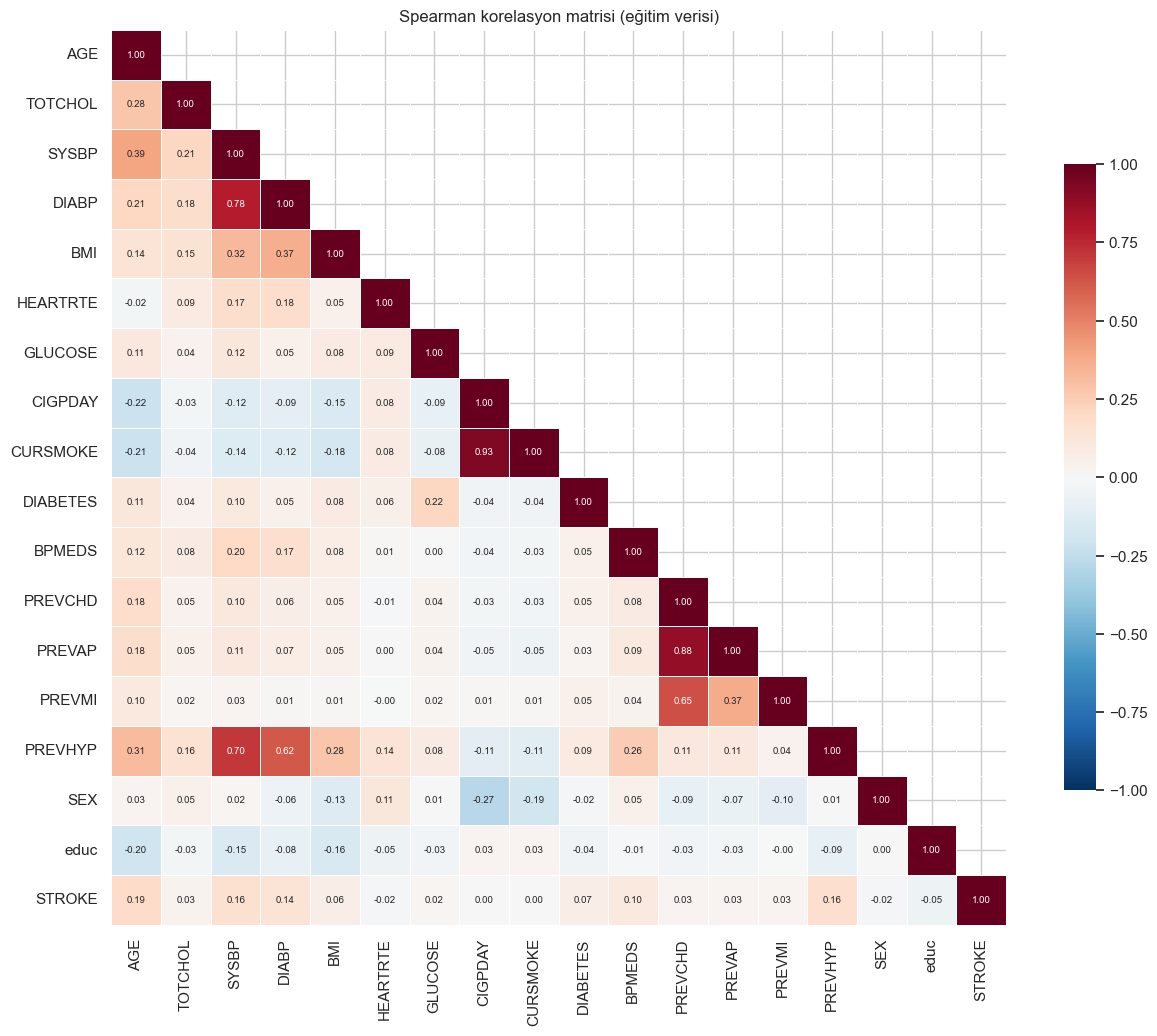

In [8]:
corr = train[CONTINUOUS + BINARY + ["SEX", "educ", TARGET]].corr(method="spearman")

fig, ax = plt.subplots(figsize=(13, 10.5))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f",
            annot_kws={"size": 7}, square=True, linewidths=0.4, cbar_kws={"shrink": 0.7}, ax=ax)
ax.set_title("Spearman korelasyon matrisi (eğitim verisi)")
plt.tight_layout()
plt.show()

In [9]:
# Correlation of each feature with the target
corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).round(3).to_frame("STROKE ile korelasyon")

,STROKE ile korelasyon
AGE,0.190
PREVHYP,0.164
SYSBP,0.162
DIABP,0.140
BPMEDS,0.096
DIABETES,0.070
BMI,0.065
educ,-0.054
TOTCHOL,0.035
PREVCHD,0.029


In [10]:
# Strongly related feature pairs (|r| >= 0.5)
features_corr = corr.drop(index=TARGET, columns=TARGET)
upper = features_corr.where(np.triu(np.ones(features_corr.shape, dtype=bool), k=1))   # each pair once
pairs = upper.stack().rename("r").reset_index().rename(columns={"level_0": "özellik 1", "level_1": "özellik 2"})
pairs[pairs["r"].abs() >= 0.5].sort_values("r", key=abs, ascending=False).round(3).reset_index(drop=True)

,özellik 1,özellik 2,r
0,CIGPDAY,CURSMOKE,0.931
1,PREVCHD,PREVAP,0.877
2,SYSBP,DIABP,0.783
3,SYSBP,PREVHYP,0.704
4,PREVCHD,PREVMI,0.646
5,DIABP,PREVHYP,0.620


**Yorum:**
- **Hedefle korelasyonlar zayıf:** En yüksekler `AGE` (0,19), `PREVHYP` (0,16), `SYSBP` (0,16) ve `DIABP` (0,14). Hiçbir özellik tek başına inmeyi güçlü şekilde açıklamıyor. Bu, projenin başındaki sorunun (README) beklenen cevabı: inme tek bir nedene bağlı değil, model risk faktörlerini **birlikte** kullanmak zorunda. Aynı zamanda modellerin PR-AUC skorunun neden 0,2 civarında kaldığını da açıklıyor.
- **Birbirine çok bağlı özellik çiftleri (çoklu doğrusallık):**
  - `CIGPDAY`–`CURSMOKE` (0,93): sigara içmeyenlerin günlük sigara sayısı 0 olduğu için doğal.
  - `PREVCHD`–`PREVAP` (0,88) ve `PREVCHD`–`PREVMI` (0,65): koroner kalp hastalığı tanımı gereği anjina ve kalp krizini kapsıyor.
  - `SYSBP`–`DIABP` (0,78), `SYSBP`–`PREVHYP` (0,70), `DIABP`–`PREVHYP` (0,62): hepsi tansiyonu ölçüyor. Feature engineering ile türetilen `pulse_pressure` ve `mean_arterial_pressure` de bu iki sütundan hesaplandığı için onlarla yüksek korelasyonlu.
- **Sonuçları:** Logistic Regression'da birbirine bağlı sütunların katsayıları tek tek yorumlanırken dikkatli olunmalı; etki sütunlar arasında paylaşılır. Düzenlileştirme (LR'de seçilen güçlü L2 cezası) bu sorunu hafifletir. Naive Bayes'in "özellikler bağımsız" varsayımı ise açıkça bozuluyor (bkz. `05_model_nb`).

## 7. Scatter plot: yaş ve büyük tansiyon

Korelasyon analizinde öne çıkan iki sürekli değişken, yaş ve büyük tansiyon, birlikte çizilir. Amaç, inme vakalarının bu iki değişkenin oluşturduğu düzlemde belirli bir bölgede toplanıp toplanmadığını ve sınıfların ne kadar iç içe geçtiğini görmektir.

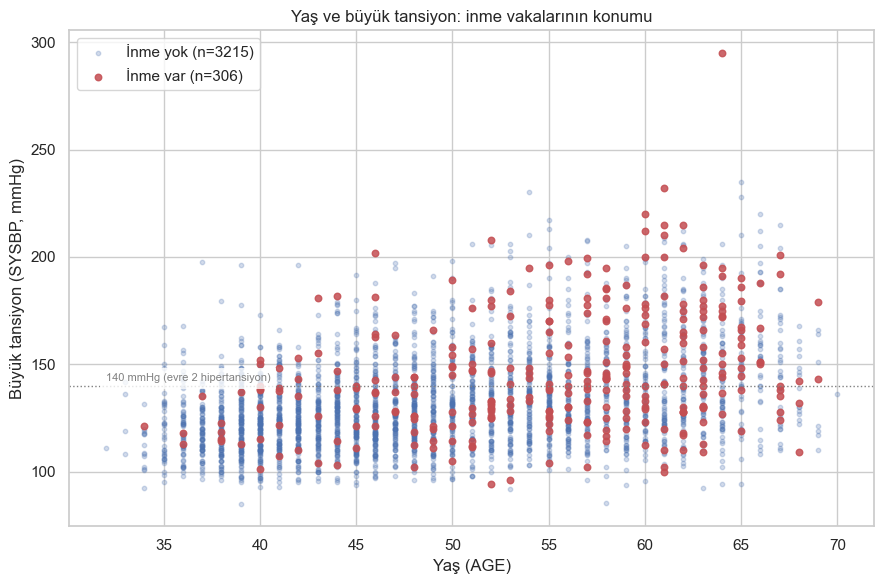

55 yaş ve üstü + SYSBP >= 140: 575 kişi, inme oranı %20.5
Geri kalan:                     2946 kişi, inme oranı %6.4


In [11]:
fig, ax = plt.subplots(figsize=(9, 6))
for name, size, alpha in [("İnme yok", 10, 0.25), ("İnme var", 22, 0.85)]:
    part = train[train["grup"] == name]
    ax.scatter(part["AGE"], part["SYSBP"], s=size, alpha=alpha, color=COLORS[name], label=f"{name} (n={len(part)})")
ax.axhline(140, color="gray", linestyle=":", linewidth=1)
ax.text(train["AGE"].min(), 142, "140 mmHg (evre 2 hipertansiyon)", fontsize=8, color="gray",
        bbox=dict(facecolor="white", edgecolor="none", alpha=0.8))
ax.set_xlabel("Yaş (AGE)")
ax.set_ylabel("Büyük tansiyon (SYSBP, mmHg)")
ax.set_title("Yaş ve büyük tansiyon: inme vakalarının konumu")
ax.legend()
plt.tight_layout()
plt.show()

old_high = (train["AGE"] >= 55) & (train["SYSBP"] >= 140)
print(f"55 yaş ve üstü + SYSBP >= 140: {old_high.sum()} kişi, inme oranı %{y_train[old_high].mean() * 100:.1f}")
print(f"Geri kalan:                     {(~old_high).sum()} kişi, inme oranı %{y_train[~old_high].mean() * 100:.1f}")

**Yorum:**
- İnme vakaları (kırmızı) grafiğin **sağ üst** bölgesinde, yani yaşlı ve tansiyonu yüksek kişilerde yoğunlaşıyor. **55 yaş ve üstü olup büyük tansiyonu 140 mmHg veya üstü** olan 575 kişide inme oranı **%20,5**, geri kalan 2.946 kişide **%6,4** (yaklaşık 3,2 kat).
- Ancak sınıflar **çok iç içe**: sağ üst bölgede bile kişilerin çoğu inme geçirmemiş, genç ve tansiyonu normal olup inme geçiren kişiler de var. İki sınıfı temiz bir şekilde ayıran bir sınır yok. Bu, hiçbir modelin çok yüksek precision'a ulaşamamasının ve %80 recall hedefinin çok sayıda yanlış alarmla sağlanabilmesinin temel nedeni.

## 8. İstatistiksel testler

Grafiklerde görülen farkların tesadüf olup olmadığı test edilir:

- **Sürekli değişkenler:** Mann-Whitney U testi. İki grubun dağılımlarını karşılaştırır, normal dağılım varsaymaz (değişkenlerimizin çoğu çarpık olduğu için t-testi yerine seçildi).
- **İkili / kategorik değişkenler:** Ki-kare bağımsızlık testi. Özellik ile inme arasında ilişki olup olmadığını sınar.

Çok sayıda test yapıldığı için anlamlılık eşiği **Bonferroni** düzeltmesiyle 0.05 / test sayısı olarak alınır.

In [12]:
rows = []
for col in CONTINUOUS:
    a, b = train.loc[y_train == 1, col], train.loc[y_train == 0, col]
    _, p = stats.mannwhitneyu(a, b, alternative="two-sided")
    rows.append({"özellik": col, "test": "Mann-Whitney U", "medyan (inme var)": a.median(),
                 "medyan (inme yok)": b.median(), "p": p})
for col in BINARY + ["SEX", "educ"]:
    _, p, _, _ = stats.chi2_contingency(pd.crosstab(train[col], y_train))
    rows.append({"özellik": col, "test": "Ki-kare", "p": p})

tests = pd.DataFrame(rows).set_index("özellik")
alpha = 0.05 / len(tests)
tests["anlamlı (Bonferroni)"] = tests["p"] < alpha
tests["p"] = tests["p"].map(lambda v: f"{v:.2e}")
print(f"Test sayısı: {len(tests)}, düzeltilmiş eşik: {alpha:.4f}")
tests.sort_values("anlamlı (Bonferroni)", ascending=False)

Test sayısı: 17, düzeltilmiş eşik: 0.0029


,test,medyan (inme var),medyan (inme yok),p,anlamlı (Bonferroni)
özellik,,,,,
AGE,Mann-Whitney U,57.00,48.00,2.39e-29,True
SYSBP,Mann-Whitney U,141.00,128.00,8.44e-22,True
DIABP,Mann-Whitney U,88.00,82.00,9.06e-17,True
BMI,Mann-Whitney U,26.41,25.38,1.25e-04,True
PREVHYP,Ki-kare,NaN,NaN,3.73e-22,True
DIABETES,Ki-kare,NaN,NaN,8.04e-05,True
BPMEDS,Ki-kare,NaN,NaN,3.10e-08,True
PREVCHD,Ki-kare,NaN,NaN,1.19e-01,False
SEX,Ki-kare,NaN,NaN,2.02e-01,False


**Yorum:**
- Bonferroni düzeltmesinden sonra (eşik 0,0029) **anlamlı** çıkan özellikler: `AGE`, `SYSBP`, `DIABP`, `BMI`, `PREVHYP`, `DIABETES`, `BPMEDS`. Bunlar grafiklerde öne çıkan yaş, tansiyon ve metabolik risk faktörleriyle aynı.
- `TOTCHOL` düzeltme öncesi sınırda anlamlı (p = 0,04), düzeltmeden sonra değil. `GLUCOSE`, `HEARTRTE`, sigara (`CURSMOKE`, `CIGPDAY`), cinsiyet ve eğitim düzeyinde inme grubuyla fark yok.
- `PREVCHD`, `PREVAP` ve `PREVMI` anlamlı çıkmadı. Ancak bu özellikleri taşıyan kişi sayısı az olduğu için testin gücü düşük. Bu sonuç "etkisi yok" değil, "bu veriyle gösterilemiyor" anlamına gelir.
- Testler her özelliğe **tek başına** bakar. Anlamlı çıkmayan bir özellik başka özelliklerle birlikte modele yine bilgi katabilir; bu yüzden özellik seçimi kararı aşağıdaki özellik seçimi deneyiyle (Bölüm 10) verilir.

## 9. Özellik önemi: Mutual Information

**Mutual information (karşılıklı bilgi)**, bir özelliği bilmenin hedef hakkındaki belirsizliği ne kadar azalttığını ölçer. 0 ise özellik hedef hakkında hiçbir bilgi taşımaz. Korelasyondan farkı, **doğrusal olmayan** ilişkileri de yakalamasıdır.

Hesaplama, modele giren hazır veri üzerinde yapılır: feature engineering ile türetilen özellikler (`pulse_pressure`, `bp_stage` vb.) de dahildir.

- **0/1 sütunlar kesikli (discrete) olarak işaretlenir.** İşaretlenmezse sklearn bunları sürekli sayı gibi ele alıp komşuluk tabanlı bir tahmin yapar; iki değerli bir sütunda bu tahmin çok gürültülü olur ve önemsiz bir sütun (ör. `CURSMOKE`) yanlışlıkla önemli görünebilir.
- Sürekli sütunların tahmini rastgeleliğe duyarlı olduğu için hesap 10 farklı tohumla yapılıp ortalaması alınır.

Modele giren özellik sayısı: 28


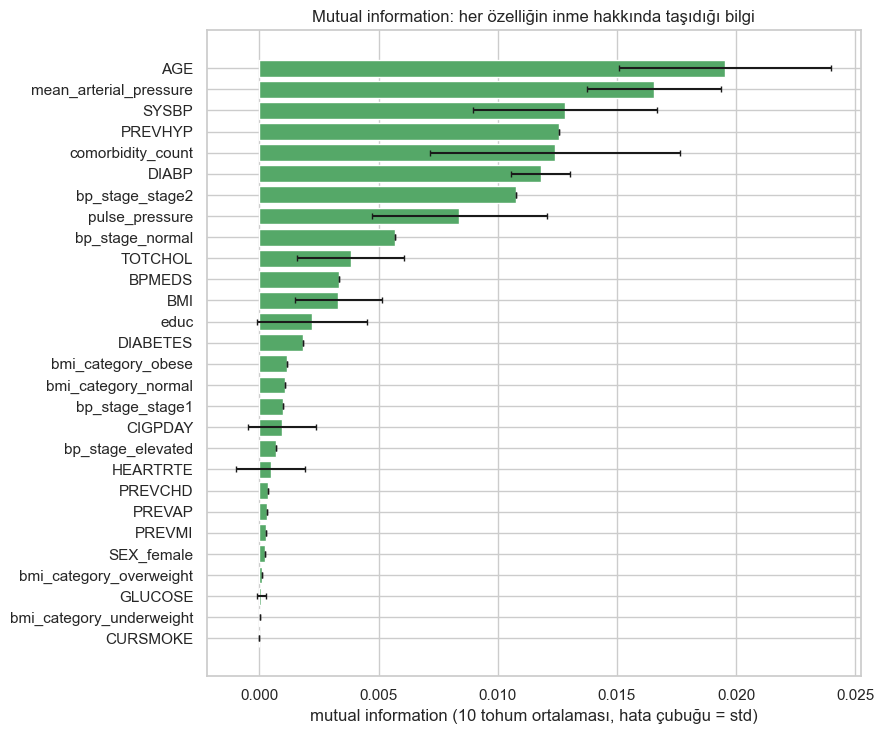

,mi,std
AGE,0.0195,0.0044
mean_arterial_pressure,0.0166,0.0028
SYSBP,0.0128,0.0039
PREVHYP,0.0126,0.0000
comorbidity_count,0.0124,0.0053
DIABP,0.0118,0.0012
bp_stage_stage2,0.0108,0.0000
pulse_pressure,0.0084,0.0037
bp_stage_normal,0.0057,0.0000
TOTCHOL,0.0038,0.0023


In [13]:
def mi_score(X, y, random_state=RANDOM_STATE):
    """Mutual information with 0/1 columns marked as discrete. Also used inside SelectKBest."""
    X = np.asarray(X, dtype=float)
    discrete = np.array([np.unique(X[:, j]).size <= 2 for j in range(X.shape[1])])
    return mutual_info_classif(X, y, discrete_features=discrete, random_state=random_state)


X_ready = build_preprocessor(feature_engineering=True).fit_transform(X_train)
print("Modele giren özellik sayısı:", X_ready.shape[1])

mi_runs = pd.DataFrame({seed: mi_score(X_ready, y_train, random_state=seed) for seed in range(10)},
                       index=X_ready.columns)
mi = pd.DataFrame({"mi": mi_runs.mean(axis=1), "std": mi_runs.std(axis=1)}).sort_values("mi", ascending=False)

fig, ax = plt.subplots(figsize=(9, 7.5))
ax.barh(mi.index[::-1], mi["mi"][::-1], xerr=mi["std"][::-1], color="#55A868", capsize=2)
ax.set_xlabel("mutual information (10 tohum ortalaması, hata çubuğu = std)")
ax.set_title("Mutual information: her özelliğin inme hakkında taşıdığı bilgi")
plt.tight_layout()
plt.show()
mi.round(4).head(12)

**Yorum:**
- Tüm değerler küçük görünüyor; bu beklenen bir durum. Hedefin kendi belirsizliği (entropisi) bu dengesizlikte yalnızca yaklaşık 0,295'tir. En bilgili özellik olan `AGE` (0,0195) bu belirsizliğin yaklaşık %6,6'sını tek başına azaltıyor.
- İlk sıralar yine **yaş ve tansiyon**: `AGE`, `mean_arterial_pressure`, `SYSBP`, `PREVHYP`, `comorbidity_count`, `DIABP`, `bp_stage_stage2`, `pulse_pressure`.
- Feature engineering ile türetilen dört özellik (`mean_arterial_pressure`, `comorbidity_count`, `bp_stage_stage2`, `pulse_pressure`) ilk 8 içinde. Bu, türetilen özelliklerin hedefle ilgili bilgi taşıdığını gösteriyor. Ancak hepsi tansiyon ve hastalık sütunlarından hesaplandığı için tamamen **yeni** bir bilgi değil, aynı bilginin modelin daha kolay kullanabileceği bir biçimi.
- Kolesterol, BMI, glikoz, nabız, sigara ve cinsiyet listenin alt sıralarında.

## 10. Özellik seçimi deneyi: daha az özellikle model daha iyi olur mu?

Önem sıralaması tek başına bir şeyi kanıtlamaz; asıl soru, önemsiz görünen özellikleri çıkarmanın modeli iyileştirip iyileştirmediğidir. Bunu ölçmek için pipeline'a bir **SelectKBest** adımı eklenir: mutual information'a göre en iyi *k* özellik seçilir, gerisi atılır. Farklı *k* değerleri ortak 5 katlı CV ile PR-AUC'ye göre karşılaştırılır.

**Önemli:** Seçim adımı pipeline'ın **içindedir**. Yani her CV katında özellikler yalnızca o katın eğitim kısmına bakılarak seçilir. Seçim tüm eğitim verisinde bir kez yapılıp sonra CV uygulansaydı, doğrulama katlarının bilgisi seçime sızardı ve skorlar olduğundan iyi çıkardı.

Deney iki farklı model ailesiyle yapılır: Logistic Regression (doğrusal) ve Random Forest (ağaç).

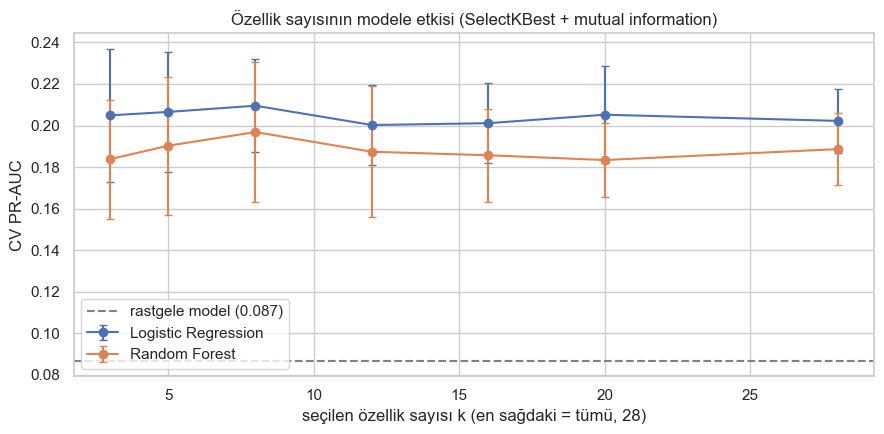

model,Logistic Regression,Random Forest
k,,
3,0.2049,0.1838
5,0.2065,0.1903
8,0.2095,0.1968
12,0.2002,0.1874
16,0.2011,0.1857
20,0.2052,0.1834
28,0.2022,0.1886


In [14]:
def selection_pipeline(model, k):
    """preprocess -> keep the k best features by mutual information -> SMOTE -> model."""
    selector = SelectKBest(mi_score, k=k)
    # imblearn does not accept a Pipeline as a step, so the preprocessor's steps (fe, encode) are unpacked
    return ImbPipeline(build_preprocessor(feature_engineering=True).steps + [
                        ("select", selector),
                        ("balance", SMOTE(random_state=RANDOM_STATE)),
                        ("model", model)])


candidates = {
    "Logistic Regression": LogisticRegression(C=0.01, max_iter=3000, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=6, min_samples_leaf=10,
                                            n_jobs=-1, random_state=RANDOM_STATE),
}
n_total = X_ready.shape[1]
k_values = [3, 5, 8, 12, 16, 20, n_total]

rows = []
for name, model in candidates.items():
    for k in k_values:
        scores = cross_val_score(selection_pipeline(model, k), X_train, y_train,
                                 cv=shared_cv(), scoring="average_precision", n_jobs=-1)
        rows.append({"model": name, "k": k, "pr_auc": scores.mean(), "std": scores.std()})
selection = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(9, 4.5))
for name, part in selection.groupby("model"):
    ax.errorbar(part["k"], part["pr_auc"], yerr=part["std"], marker="o", capsize=3, label=name)
ax.axhline(y_train.mean(), color="gray", linestyle="--", label=f"rastgele model ({y_train.mean():.3f})")
ax.set_xlabel(f"seçilen özellik sayısı k (en sağdaki = tümü, {n_total})")
ax.set_ylabel("CV PR-AUC")
ax.set_title("Özellik sayısının modele etkisi (SelectKBest + mutual information)")
ax.legend()
plt.tight_layout()
plt.show()
selection.pivot(index="k", columns="model", values="pr_auc").round(4)

In [15]:
# Which features survive when k is small? (selection on the full training data, for reporting only)
for k in [5, 8, 12]:
    sel = SelectKBest(mi_score, k=k).fit(X_ready, y_train)
    print(f"k={k:2d}:", list(X_ready.columns[sel.get_support()]))

k= 5: ['AGE', 'SYSBP', 'DIABP', 'mean_arterial_pressure', 'PREVHYP']
k= 8: ['AGE', 'SYSBP', 'DIABP', 'mean_arterial_pressure', 'comorbidity_count', 'bp_stage_normal', 'bp_stage_stage2', 'PREVHYP']
k=12: ['AGE', 'SYSBP', 'DIABP', 'BMI', 'CIGPDAY', 'pulse_pressure', 'mean_arterial_pressure', 'comorbidity_count', 'bp_stage_normal', 'bp_stage_stage2', 'BPMEDS', 'PREVHYP']


**Yorum:**
- **Özellik sayısı skoru anlamlı şekilde değiştirmiyor.** Logistic Regression'da tüm 28 özellikle CV PR-AUC 0,202 ± 0,015; en iyi alt küme (k = 8) 0,210 ± 0,023. Fark 0,007, katlar arası standart sapmanın çok altında. Random Forest'ta da durum aynı: tüm özelliklerle 0,189, en iyi k ile 0,197.
- **Yalnızca 3 özellikle bile skor neredeyse aynı** (LR'de 0,205). Bu, verideki tahmin gücünün büyük kısmının birkaç yaş ve tansiyon özelliğinde toplandığını, diğer özelliklerin çok az şey eklediğini doğruluyor.
- Küçük *k* değerlerinde seçilen özellikler beklenen risk faktörleri: k = 5'te `AGE`, `SYSBP`, `DIABP`, `mean_arterial_pressure`, `PREVHYP`.
- (Buradaki modeller ayarlanmamış, sabit hiperparametreli modellerdir; amaç yalnızca özellik sayısının etkisini görmek. Bu yüzden skorlar model notebook'larındaki ayarlanmış skorlardan biraz farklıdır.)

**Karar: Tüm özellikler modelde tutuldu.** Gerekçeler:
1. Özellik azaltmak CV skorunu anlamlı şekilde iyileştirmedi; fark katlar arası değişkenliğin içinde kaldı.
2. Veri seti küçük (yalnızca 306 inme vakası). Seçilen alt küme katlara göre değişebiliyor; az sayıda özelliğe sabitlenmek o örnekleme özgü bir seçim olabilir.
3. Modeller zaten kendi içinde özellik seçimi yapıyor (gömülü / embedded seçim): Logistic Regression'da L1/L2 düzenlileştirme önemsiz katsayıları küçültüyor, ağaç modellerinde `max_depth` ve `min_samples_leaf` gereksiz bölünmeleri engelliyor.
4. Açıklanabilir yapay zeka kısmında (SHAP, LIME) tüm risk faktörlerinin katkısını görmek istiyoruz. Örneğin sigaranın neden önemsiz çıktığı, ancak modelde bulunursa tartışılabilir.

## 11. Özet (rapor için)

**Veri analizi (yalnızca eğitim verisi, 3.521 kişi, %8,7 inme)**
- Sınıflar dengesiz: her inme vakasına 10,5 sağlıklı kişi düşüyor.
- **Yaş** ve **tansiyon**, inme ile en güçlü ilişkili değişkenler. İnme oranı yaşla 8 kat (%2,2 → %18,1), büyük tansiyonla 6 kat (%4,3 → %26,8) artıyor. 55 yaş ve üstü olup tansiyonu 140 mmHg veya üstü olanlarda oran %20,5, diğerlerinde %6,4.
- İkili risk faktörlerinden tansiyon ilacı (göreli risk 2,9), hipertansiyon öyküsü (2,8) ve diyabet (2,4) öne çıkıyor. Sigara bu veride tek başına inmeyle ilişkisiz görünüyor; sigara içenlerin daha genç olması (karıştırıcı etki) olası bir açıklama.
- Hedefle korelasyonlar zayıf (en yüksek 0,19): inme tek bir değişkenle açıklanamıyor ve sınıflar iç içe geçmiş durumda. Bu, modellerin PR-AUC skorunun neden sınırlı kaldığını açıklıyor.
- Tansiyon sütunları (`SYSBP`, `DIABP`, `PREVHYP`, türetilen tansiyon özellikleri), sigara sütunları ve kalp hastalığı sütunları birbirine çok bağlı (çoklu doğrusallık).
- Mann-Whitney U ve ki-kare testlerinde (Bonferroni düzeltmesiyle) anlamlı çıkanlar: `AGE`, `SYSBP`, `DIABP`, `BMI`, `PREVHYP`, `DIABETES`, `BPMEDS`.

**Özellik önemi ve seçimi**
- Özellik önemi filtre yöntemi olan **mutual information** ile ölçüldü (0/1 sütunlar kesikli olarak işaretlendi). Seçim kararı için **SelectKBest ile özellik sayısı deneyi** yapıldı; seçim pipeline içinde, her CV katında yalnızca eğitim kısmında uygulandı.
- İstatistiksel testler ve mutual information, yaş ve tansiyonu en önemli özellikler olarak gösterdi. Feature engineering ile türetilen tansiyon özellikleri mutual information'da ilk sıralarda yer aldı.
- Özellik sayısını 28'den 3–20'ye indirmek CV PR-AUC'yi anlamlı şekilde değiştirmedi (farklar katlar arası standart sapmanın altında). Bu yüzden **tüm özellikler tutuldu**. Gereksiz özelliklerin etkisi modellerin kendi düzenlileştirmesiyle (LR'de L1/L2 cezası, ağaçlarda derinlik ve yaprak sınırı) kontrol edildi.
- Model bazında özellik önemleri, her modelin notebook'unda SHAP ile ayrıca incelenmiştir (`04_explainability`, `09_model_comparison`).